# 68 — Visual tokens and multimodal fusion

CLIP compares one global image vector with one global text vector. A model that must answer detailed questions or generate grounded text usually needs more local information. It therefore preserves an image as a sequence of visual tokens and lets those tokens interact with text tokens.

This notebook follows that path with a tiny synthetic image. We focus on tensor shapes and information flow rather than training a large vision-language model.

## Learning goals

- Convert an image into a sequence of patch tokens.
- Explain why a connector maps visual and text features to a common width.
- Add position and modality information to tokens.
- Construct padding masks for mixed visual–text sequences.
- Distinguish joint self-attention from text-to-image cross-attention.
- Visualize which image patches a text query attends to.

In [43]:
import math

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from torch import nn

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device("cpu")
print("device:", device)

device: cpu


## 1. A small image with visible regions

We use an 8 × 8 RGB image divided into four colored quadrants. Its simple structure lets us verify exactly which patch corresponds to which region.

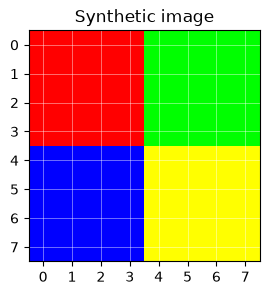

In [44]:
image = torch.zeros(3, 8, 8)
image[:, :4, :4] = torch.tensor([1.0, 0.0, 0.0])[:, None, None]   # red
image[:, :4, 4:] = torch.tensor([0.0, 1.0, 0.0])[:, None, None]   # green
image[:, 4:, :4] = torch.tensor([0.0, 0.0, 1.0])[:, None, None]   # blue
image[:, 4:, 4:] = torch.tensor([1.0, 1.0, 0.0])[:, None, None]   # yellow

plt.figure(figsize=(3, 3))
plt.imshow(image.permute(1, 2, 0))
plt.xticks(range(8))
plt.yticks(range(8))
plt.grid(color="white", linewidth=0.5, alpha=0.6)
plt.title("Synthetic image")
plt.show()

In [45]:
(
    torch.tensor([1.0, 0.0, 0.0]).shape,
    torch.tensor([1.0, 0.0, 0.0])[:, None, None].shape
)

(torch.Size([3]), torch.Size([3, 1, 1]))

## 2. Image patches become visual tokens

For non-overlapping square patches of width $P$, an image with shape $(N,C,H,W)$ becomes

$$
(N,L,CP^2),
\qquad
L=\frac{H}{P}\frac{W}{P}.
$$

Each of the $L$ rows is one flattened local patch. The ordering is row-major: move left to right across one patch row, then continue on the next row.

### Exercise 1 — Implement patchification

Use two tensor unfold operations, then rearrange the result into a token sequence. Verify that an 8 × 8 image with patch size 2 produces 16 tokens, each containing $3\times2\times2=12$ values.

In [46]:
def patchify(images, patch_size):
    if images.ndim != 4:
        raise ValueError("images must have shape (N, C, H, W)")
    batch_size, channels, height, width = images.shape
    if height % patch_size != 0 or width % patch_size != 0:
        raise ValueError("height and width must be divisible by patch_size")

    # unfold height and width into non-overlapping patches.
    patches = torch.nn.functional.unfold(images, kernel_size=patch_size, stride=patch_size)
    # print("patches shape:", patches.shape)  # (N, C * P * P, L), where L = number of patches
    # F.unfold returns (N, C * P * P, L); move L before patch features.
    patch_tokens = patches.permute(0, 2, 1).reshape(batch_size, -1, channels * patch_size * patch_size)
    # print("patch_tokens shape:", patch_tokens.shape)  # (N, L, C * P * P)
    return patch_tokens


images = image.unsqueeze(0)
patch_pixels = patchify(images, patch_size=2)
print("image batch:", images.shape)
print("patch tokens:", patch_pixels.shape)

assert patch_pixels.shape == (1, 16, 12)

image batch: torch.Size([1, 3, 8, 8])
patch tokens: torch.Size([1, 16, 12])


### Exercise 2 — Reconstruct and label the patch grid

Reshape every flattened token back to a small RGB patch and show all 16 patches in their sequence order. This confirms that token index is connected to a spatial location before any position embedding is added.

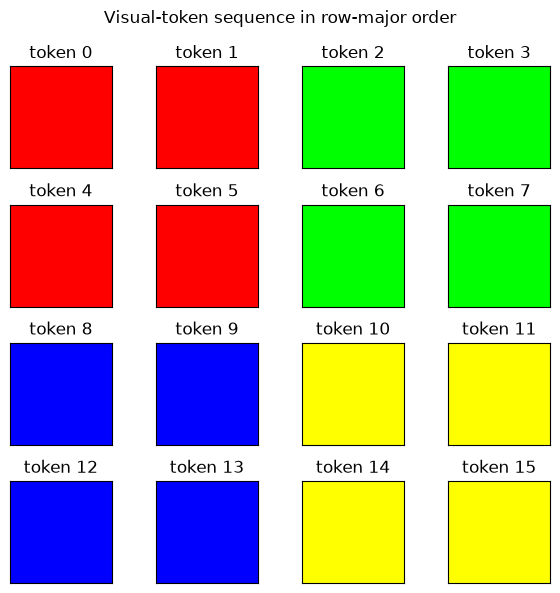

In [47]:
figure, axes = plt.subplots(4, 4, figsize=(6, 6))

for token_index, axis in enumerate(axes.ravel()):
    # restore token (12,) to one RGB patch shaped (2, 2, 3).
    patch_image = patch_pixels[0, token_index].reshape(3, 2, 2).permute(1, 2, 0)
    axis.imshow(patch_image)
    axis.set_title(f"token {token_index}")
    axis.set_xticks([])
    axis.set_yticks([])

plt.suptitle("Visual-token sequence in row-major order")
plt.tight_layout()

## 3. Projection and connector layers

A flattened patch has width $CP^2$, but the language model may use a different width $D$. A learned projection maps every patch independently into that shared model width:

$$
X_{visual}\in\mathbb{R}^{N\times L_v\times CP^2}
\longrightarrow
V\in\mathbb{R}^{N\times L_v\times D}.
$$

In a real VLM, the input may instead be features from a pretrained vision encoder. The connector still performs the essential interface job: it maps visual features into the width and representation space expected by the multimodal or language model.

### Exercise 3 — Project patches and add positions

Apply the same linear projection to every patch and add one learned positional vector per visual-token index.

In [48]:
MODEL_DIMENSION = 16
number_visual_tokens = patch_pixels.shape[1]
patch_projection = nn.Linear(patch_pixels.shape[2], MODEL_DIMENSION)
visual_position_embeddings = nn.Parameter(
    torch.randn(1, number_visual_tokens, MODEL_DIMENSION) * 0.02
)

# project patch_pixels and add visual_position_embeddings.
visual_tokens = patch_projection(patch_pixels) + visual_position_embeddings

print("visual tokens:", visual_tokens.shape)
assert visual_tokens.shape == (1, 16, MODEL_DIMENSION)

visual tokens: torch.Size([1, 16, 16])


## 4. Text tokens and padding

Text tokens already begin as discrete IDs. An embedding table maps them to width $D$. Different sentences can have different lengths, so shorter rows contain padding tokens that attention must ignore.

Position answers “where is this token in its own sequence?” A modality embedding answers “did this token come from the image or the text?” These are different signals.

### Exercise 4 — Encode text and construct valid-token masks

In [49]:
vocabulary = {
    "<pad>": 0,
    "where": 1,
    "is": 2,
    "red": 3,
    "blue": 4,
    "?": 5,
}
text_ids = torch.tensor(
    [
        [1, 2, 3, 5],       # where is red ?
        [1, 2, 4, 5],       # where is blue ?
        [3, 5, 0, 0],       # red ? <pad> <pad>
    ]
)

text_embedding = nn.Embedding(len(vocabulary), MODEL_DIMENSION, padding_idx=0)
# Learn one vector per sequence position and broadcast it across the batch.
text_position_embeddings = nn.Parameter(
    torch.randn(1, text_ids.shape[1], MODEL_DIMENSION) * 0.02
)

# mark non-padding IDs as valid and embed the text IDs.
text_valid = text_ids != vocabulary["<pad>"]
text_tokens = text_embedding(text_ids)
# add a positional embedding to every text-token representation.
text_tokens = text_tokens + text_position_embeddings

print("text IDs:", text_ids.shape)
print("text tokens:", text_tokens.shape)
print("valid tokens:\n", text_valid)

assert text_tokens.shape == (3, 4, MODEL_DIMENSION)
assert text_valid.sum(dim=1).tolist() == [4, 4, 2]

text IDs: torch.Size([3, 4])
text tokens: torch.Size([3, 4, 16])
valid tokens:
 tensor([[ True,  True,  True,  True],
        [ True,  True,  True,  True],
        [ True,  True, False, False]])


## 5. Joint sequence fusion

One fusion strategy places visual and text tokens in one sequence:

$$
[v_1,\ldots,v_{L_v},t_1,\ldots,t_{L_t}].
$$

Self-attention can then create image-to-image, image-to-text, text-to-image, and text-to-text interactions in the same attention matrix. Visual tokens are all valid here; padded text positions are not.

Because our visual batch contains one image but the text batch contains three questions, the image tokens must first be expanded across the three examples. Expansion reuses the same values without creating three independently learned images.

### Exercise 5 — Assemble the multimodal sequence

In [50]:
batch_size = text_ids.shape[0]
image_modality = nn.Parameter(torch.randn(1, 1, MODEL_DIMENSION) * 0.02)
text_modality = nn.Parameter(torch.randn(1, 1, MODEL_DIMENSION) * 0.02)

# expand visual_tokens from batch size 1 to batch_size.
visual_tokens_batch = visual_tokens.expand(batch_size, -1, -1)
# add the corresponding modality embedding to visual and text tokens.
visual_tokens_with_modality = visual_tokens_batch + image_modality
text_tokens_with_modality = text_tokens + text_modality
# concatenate visual tokens before text tokens along the sequence axis.
joint_tokens = torch.cat([visual_tokens_with_modality, text_tokens_with_modality], dim=1)

visual_valid = torch.ones(
    batch_size, number_visual_tokens, dtype=torch.bool
)
# concatenate the visual and text validity masks.
joint_valid = torch.cat([visual_valid, text_valid], dim=1)

print("joint tokens:", joint_tokens.shape)
print("joint valid mask:", joint_valid.shape)

assert joint_tokens.shape == (3, 20, MODEL_DIMENSION)
assert joint_valid.shape == (3, 20)

joint tokens: torch.Size([3, 20, 16])
joint valid mask: torch.Size([3, 20])


### Exercise 6 — Run joint self-attention

PyTorch MultiheadAttention expects key_padding_mask to mark ignored positions with True—the opposite convention from joint_valid. Request per-head weights so their shape remains explicit.

The resulting attention weights have shape $(N,H,L,L)$. Both query and key lengths equal the complete multimodal sequence length.

In [51]:
joint_attention = nn.MultiheadAttention(
    MODEL_DIMENSION, num_heads=4, batch_first=True
)

# invert joint_valid for key_padding_mask and apply self-attention.
ignored_keys = ~joint_valid
joint_output, joint_attention_weights = joint_attention(
    query=joint_tokens,
    key=joint_tokens,
    value=joint_tokens,
    key_padding_mask=ignored_keys,
    need_weights=True,
    average_attn_weights=False,
)

print("joint output:", joint_output.shape)
print("attention weights:", joint_attention_weights.shape)

assert joint_output.shape == joint_tokens.shape
assert joint_attention_weights.shape == (3, 4, 20, 20)
assert torch.all(joint_attention_weights[2, :, :, -2:] == 0)

joint output: torch.Size([3, 20, 16])
attention weights: torch.Size([3, 4, 20, 20])


## 6. Cross-attention: text asks, image answers

Joint self-attention treats all tokens as one sequence. Cross-attention keeps two streams distinct:

- queries come from text tokens;
- keys describe which visual locations are available;
- values carry the visual information retrieved from those locations.

Its attention matrix has shape $(N,H_{\text{heads}},L_t,L_v)$: every text position distributes attention across image locations. Here $H_{\text{heads}}$ is the number of attention heads, not the image height commonly denoted by $H$ in an image shape such as $(N,C,H,W)$. Cross-attention does not require the query and key sequences to have equal length.

### Exercise 7 — Build an interpretable color-to-patch attention map

To make the behavior understandable before training, use each patch's mean RGB value as its key and use RGB color vectors as text queries. Compute scaled dot products, apply softmax across visual keys, and reshape each query's 16 weights to a 4 × 4 patch grid.

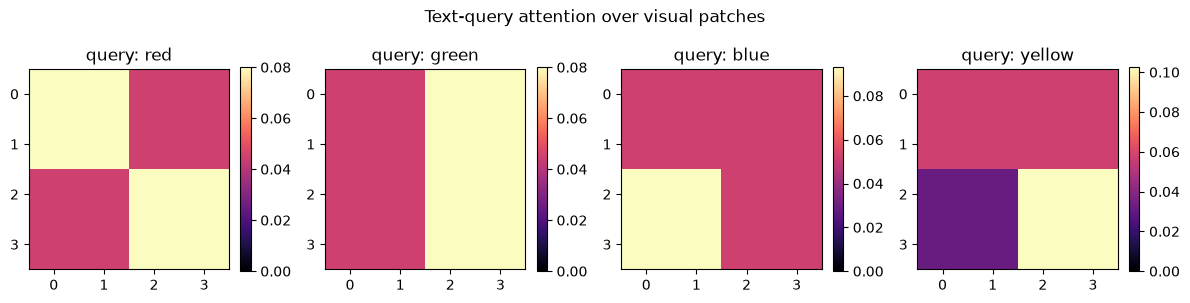

In [52]:
# Recover patches as (N, L, C, P, P), then summarize each patch by mean RGB.
patch_images = patch_pixels.reshape(1, 16, 3, 2, 2)
visual_color_keys = patch_images.mean(dim=(3, 4))

query_names = ("red", "green", "blue", "yellow")
color_queries = torch.tensor(
    [
        [1.0, 0.0, 0.0],
        [0.0, 1.0, 0.0],
        [0.0, 0.0, 1.0],
        [1.0, 1.0, 0.0],
    ]
).unsqueeze(0)

# calculate scores shaped (1, 4, 16). Transpose only the final two
# key dimensions, divide by sqrt(3), and softmax across the visual-token axis.
color_scores = torch.einsum("bqc,bkc->bqk", color_queries, visual_color_keys) / math.sqrt(3)
# color_scores = (
#     color_queries @ visual_color_keys.transpose(-2, -1)
# ) / math.sqrt(3)
color_attention = F.softmax(color_scores, dim=-1)

figure, axes = plt.subplots(1, 4, figsize=(12, 3))
for query_index, axis in enumerate(axes):
    attention_map = color_attention[0, query_index].reshape(4, 4)
    image_artist = axis.imshow(attention_map, cmap="magma", vmin=0)
    axis.set_title(f"query: {query_names[query_index]}")
    axis.set_xticks(range(4))
    axis.set_yticks(range(4))
    figure.colorbar(image_artist, ax=axis, fraction=0.046)

plt.suptitle("Text-query attention over visual patches")
plt.tight_layout()

assert color_attention.shape == (1, 4, 16)
torch.testing.assert_close(
    color_attention.sum(dim=-1), torch.ones(1, 4)
)

## 7. Common fusion patterns

| Pattern | Main interaction | Attention score shape | Typical intuition |
| --- | --- | --- | --- |
| Global dual encoder | Compare pooled image and text vectors | $N\times N$ across examples | Efficient retrieval and zero-shot classification |
| Joint self-attention | Mix one combined visual–text sequence | $(L_v+L_t)^2$ per head | Every token can directly interact with every other token |
| Cross-attention | One modality queries another | $L_tL_v$ per head | Text selectively reads visual information |
| Connector plus language model | Insert projected visual tokens into an LM | Depends on LM sequence | Generate text conditioned on visual tokens |

Architectures often combine these patterns. For example, a vision encoder can first use visual self-attention, a connector can reduce or project its tokens, and a language model can then consume them through cross-attention or as part of its token sequence.

## 8. Scope and limitations

The color-query example uses handcrafted features so that attention has an immediately interpretable result. A real model learns its query, key, and value projections from data; its feature dimensions need not correspond directly to red, green, or blue.

Attention weights show where one attention operation reads information, but they are not automatically a complete explanation of the model's final decision. Later layers, residual connections, and value projections can all change how that information is used.

## Reflection

1. What information is lost when an entire image is reduced to one global embedding, compared with retaining patch tokens?

   Local spatial detail can be compressed: which region contains a feature, how several objects relate, and which patch should be grounded to a word. A global embedding may retain broad scene information but no longer exposes one token per location.

2. Why must visual and text tokens have the same feature width before they can participate in one attention module?

   Attention compares queries and keys with dot products, so their projected feature widths must match. A shared model width also lets visual and text tokens be stored and processed in one sequence.

3. What different information do positional and modality embeddings provide?

   A positional embedding identifies where a token occurs in its sequence or patch grid. A modality embedding identifies whether that token came from the image or the text.

4. In text-to-image cross-attention, why does the attention matrix use text length for rows and visual-token length for columns?

   Each row belongs to one text query, and its columns contain the attention weights assigned to every visual key. Therefore the two axes have lengths $L_t$ and $L_v$.

5. How does joint self-attention differ from cross-attention in which token pairs it can represent directly?

   Joint self-attention can directly represent visual–visual, visual–text, text–visual, and text–text interactions. Text-to-image cross-attention directly represents only text queries reading visual keys and values.

6. Why should attention weights be interpreted cautiously rather than treated as a complete explanation?

   They describe where one attention operation reads, not the complete causal contribution to the prediction. Value projections, residual paths, other heads, and later layers can change how the attended information is used.